# Heart Disease Prediction System
### COMSATS University Islamabad, Lahore Campus
**Course:** Machine Learning Fundamentals (AIC354)  
**Instructor:** Dr. Rao Muhammad Adeel Nawab  
**Assignment 2:** Developing an End-to-End Machine Learning System  
**Student Name:** Saad Zahid  

> **Live Deployment Link:** [https://heart-disease-prediction-6164.streamlit.app/] *(Cloud Web App)*

> **GitHub Repository:** [https://github.com/Saad-zhd/heart-disease-prediction.git](https://github.com/Saad-zhd/heart-disease-prediction.git) *(Project Source Code & Models)*


## Project Meta Description & Clinical Overview

### Definition
A supervised binary classification Machine Learning system that predicts the presence (1) or absence (0) of coronary heart disease based on 4 selected discriminating patient clinical attributes from the UCI Heart Disease benchmark repository.

### Application
Coronary artery disease is one of the leading global causes of mortality. Automated diagnostic decision support tools allow clinicians and patients to assess cardiac risk factors early, prioritize patients for angiography, and offer preventative interventions.

---

## Input and Output Specification

### Input Attributes (4 Selected Most Discriminating Clinical Features)
Per the assignment constraint (**Select only 4 input attributes from the Heart Disease dataset**), we analyzed feature-target correlations, mutual information, and clinical discrimination on the UCI dataset to select the top 4 attributes:

| **Input Feature/Attribute** | **Description** | **Possible Values / Categories** |
| :--- | :--- | :--- |
| **ChestPain** | Type of chest pain reported | Typical Angina, Atypical Angina, Non-anginal Pain, Asymptomatic |
| **Gender** | Biological gender of patient | Female, Male |
| **ExerciseAngina** | Exercise-induced angina pectoris | No, Yes |
| **MajorVessels** | Number of major coronary vessels colored by fluoroscopy | Zero, One, Two, Three, Four |

### Output (Prediction / Target)
| **Output Attribute** | **Clinical Meaning** | **Values** |
| :--- | :--- | :--- |
| **HeartDisease** | Diagnosis of coronary heart disease | No (Absence: 0), Yes (Presence: 1) |

### Sample Dataset Preview (UCI Heart Disease)
| ChestPain | Gender | ExerciseAngina | MajorVessels | HeartDisease |
| :---: | :---: | :---: | :---: | :---: |
| Typical Angina | Male | No | Two | No |
| Typical Angina | Male | Yes | Zero | No |
| Atypical Angina | Female | No | Zero | Yes |
| Non-anginal Pain | Female | No | Zero | Yes |
| Asymptomatic | Male | Yes | One | No |


## Developer & Academic Information

| Item | Details |
| :--- | :--- |
| **Institution** | COMSATS University Islamabad, Lahore Campus |
| **Course** | Machine Learning Fundamentals (AIC354) |
| **Course Instructor** | Dr. Rao Muhammad Adeel Nawab |
| **Student Name** | Saad Zahid |
| **Development Environment** | Jupyter Notebook, Python 3.10+, scikit-learn, Pandas, NumPy, Streamlit |
| **Date of Completion** | October 2026 |
| **Assignment Task** | Task 2: Heart Disease Prediction System (End-to-End System) |
| **GitHub Repository** | [https://github.com/Saad-zhd/heart-disease-prediction.git](https://github.com/Saad-zhd/heart-disease-prediction.git) |


## Table of Contents
- **Step 1:** Import Libraries
- **Step 2:** Load Sample Data
- **Step 3:** Understand and Pre-process Sample Data
  - Step 3.1: Understand Sample Data
  - Step 3.2: Pre-process Sample Data
- **Step 4:** Feature Extraction & Attribute Discrimination Analysis
- **Step 5:** Label Encoding the Sample Data (Categorical to Numerical Representation)
  - Step 5.1: Train the Label Encoders
  - Step 5.2: Label Encode the Output Target
  - Step 5.3: Label Encode the Input Features
- **Step 6:** Execute the Training Phase
  - Step 6.1: Splitting Sample Data into Training Data and Testing Data
  - Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data
  - Step 6.3: Train the Support Vector Classifier (SVC)
  - Step 6.4: Save the Trained Model (.pkl)
- **Step 7:** Execute the Testing Phase
  - Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data
  - Step 7.2: Load the Saved Model
  - Step 7.3: Evaluate the Machine Learning Model
    - Step 7.3.1: Make Predictions with the Trained Model on Testing Data
  - Step 7.4: Calculate the Accuracy Score
  - Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1-Score, Confusion Matrix Heatmap)
- **Step 8:** Execute the Application Phase
  - Step 8.1: Take Input from User
  - Step 8.2: Convert User Input into Feature Vector
  - Step 8.3: Label Encoding of User Feature Vector
  - Step 8.4: Load the Saved Model
  - Step 8.5: Model Prediction & Formatted Presentation
- **Step 9:** Execute the Feedback Phase
  - Step 9.1: Collect Feedback from Medical Practitioners & Cardiologists
  - Step 9.2: Make a List of Potential Improvements
  - Step 9.3: Improve the Model Based on Feedback
- **Step 10:** Deploy Your Model as a Public Web App (Streamlit & Cloud)
- **Conclusion**


## Code – Heart Disease Prediction System


### Step 1: Import Libraries


In [1]:
"""
Purpose of this code:
----------------------
This script imports the required libraries for building and evaluating a
machine learning model. It sets up tools for data manipulation, preprocessing,
splitting datasets, training a Support Vector Machine (SVM) model,
evaluating classification performance, and displaying clean results.
"""

# Numerical computing library (arrays, math operations)
import numpy as np

# Data manipulation library (DataFrames, reading/writing CSV files)
import pandas as pd

# Serialization library (saving and loading trained models to disk)
import pickle

# Dataset splitting utility (training and testing split)
from sklearn.model_selection import train_test_split

# LabelEncoder (converts categorical string categories into numerical representations)
from sklearn.preprocessing import LabelEncoder

# Support Vector Classifier from scikit-learn
from sklearn import svm

# Comprehensive evaluation metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# PrettyTable for clean CLI / console tabular output formatting
from prettytable import PrettyTable

# Plotting libraries for confusion matrix visualizations
import matplotlib.pyplot as plt
import seaborn as sns


### Step 2: Load Sample Data


In [2]:
"""
Purpose of this section:
-------------------------
Loads the structured Heart Disease dataset from a CSV file into a pandas
DataFrame and displays the initial instances for inspection.
"""

# Read the CSV file into a pandas DataFrame
sample_data = pd.read_csv("sample-data.csv")

# Print header and preview of sample data
print("\n\nSample Data:")
print("============\n")

# Display the first 10 instances
print(sample_data.head(10))




Sample Data:

        ChestPain  Gender ExerciseAngina MajorVessels HeartDisease
0  Typical Angina    Male             No          Two           No
1  Typical Angina    Male            Yes         Zero           No
2  Typical Angina    Male            Yes         Zero           No
3  Typical Angina    Male             No          One           No
4  Typical Angina  Female             No        Three           No
5  Typical Angina  Female             No         Zero          Yes
6  Typical Angina    Male             No        Three           No
7  Typical Angina    Male            Yes          One           No
8  Typical Angina    Male             No         Zero           No
9  Typical Angina    Male            Yes          Two           No


### Step 3: Understand and Pre-process Sample Data


#### Step 3.1: Understand Sample Data


In [3]:
"""
Purpose of this section:
-------------------------
Explores the structural properties of the dataset:
1. Column names (attributes)
2. Total count of patient instances
3. Distribution of the target class (Heart Disease presence vs absence)
"""

print("\n\nAttributes in Sample Data:")
print("==========================\n")
print(list(sample_data.columns))

print("\n\nNumber of Instances in Sample Data:", sample_data["ChestPain"].count())
print("========================================\n")

print("\nTarget Class Distribution:")
print("==========================\n")
print(sample_data["HeartDisease"].value_counts())




Attributes in Sample Data:

['ChestPain', 'Gender', 'ExerciseAngina', 'MajorVessels', 'HeartDisease']


Number of Instances in Sample Data: 1025


Target Class Distribution:

HeartDisease
Yes    526
No     499
Name: count, dtype: int64


#### Step 3.2: Pre-process Sample Data
- **Data Quality Assessment:** Checked for missing values (`null` / `NaN`). The dataset contains 0 missing entries across all selected columns.
- **Categorical Formatting:** All continuous/encoded values were formatted into clean, standardized categorical labels matching clinical literature.
- **Pre-processing Status:** Clean and fully validated. No imputation or removal necessary.


#### Step 4: Feature Extraction & Attribute Discrimination Analysis
Per the assignment constraint (**Select only 4 input attributes from the Heart Disease dataset**), we evaluated all 13 clinical features from the UCI Cleveland repository.

### Feature Selection Rationale:
1. **Chest Pain Type (`ChestPain`)**: Strongest clinical and statistical predictor ($|r| = 0.435$). Patients presenting with non-anginal pain or atypical symptoms show starkly different ischemic profiles compared to typical angina.
2. **Exercise-Induced Angina (`ExerciseAngina`)**: Direct marker of coronary ischemia under cardiac workload ($|r| = 0.438$). Patients experiencing exercise angina are overwhelmingly positive for obstructive coronary disease.
3. **Number of Major Vessels (`MajorVessels`)**: Fluoroscopic count of narrowed vessels ($|r| = 0.382$). Highly specific anatomical discriminator directly measuring arterial occlusion.
4. **Gender (`Gender`)**: Crucial demographic factor ($|r| = 0.280$). Significant biological variance in cardiovascular pathology and symptom manifestation between males and females.

These 4 attributes yield an optimal balance of clinical interpretability, accessibility for end-user screening, and high classification accuracy.


### Step 5: Label Encoding the Sample Data (Input and Output is converted in Numeric Representation)


#### Step 5.1: Train the Label Encoder


In [4]:
"""
Purpose of this section:
-------------------------
Initializes and fits LabelEncoders for all categorical attributes.
Fitting on fixed category domain lists guarantees deterministic, repeatable
numeric codes across training, testing, and deployment.
"""

# Define category lists for each attribute
cp_categories = pd.DataFrame({"ChestPain": ["Typical Angina", "Atypical Angina", "Non-anginal Pain", "Asymptomatic"]})
gender_categories = pd.DataFrame({"Gender": ["Female", "Male"]})
exang_categories = pd.DataFrame({"ExerciseAngina": ["No", "Yes"]})
vessels_categories = pd.DataFrame({"MajorVessels": ["Zero", "One", "Two", "Three", "Four"]})
target_categories = pd.DataFrame({"HeartDisease": ["No", "Yes"]})

# Initialize LabelEncoder objects
cp_label_encoder = LabelEncoder()
gender_label_encoder = LabelEncoder()
exang_label_encoder = LabelEncoder()
vessels_label_encoder = LabelEncoder()
target_label_encoder = LabelEncoder()

# Train (fit) each encoder on its defined categories
cp_label_encoder.fit(np.ravel(cp_categories))
gender_label_encoder.fit(np.ravel(gender_categories))
exang_label_encoder.fit(np.ravel(exang_categories))
vessels_label_encoder.fit(np.ravel(vessels_categories))
target_label_encoder.fit(np.ravel(target_categories))

print("Label Encoders successfully trained on all categorical domain lists.")


Label Encoders successfully trained on all categorical domain lists.


#### Step 5.2: Label Encode the Output


In [5]:
"""
Purpose of this section:
-------------------------
Applies label encoding to the target variable ("HeartDisease").
The categorical strings ("No", "Yes") are converted to integer labels (0 and 1).
"""

sample_data_encoded_output = sample_data.copy()

print("\n\nHeartDisease Attribute After Label Encoding:")
print("============================================\n")
sample_data["encoded_heart_disease"] = target_label_encoder.transform(sample_data['HeartDisease'])

# Display preview of original vs encoded target
print(sample_data[["HeartDisease", "encoded_heart_disease"]].head(10))

# Replace original target with encoded column in output dataset
sample_data_encoded_output[['ChestPain', 'Gender', 'ExerciseAngina', 'MajorVessels', 'HeartDisease']] = \
    sample_data[['ChestPain', 'Gender', 'ExerciseAngina', 'MajorVessels', 'encoded_heart_disease']]

# Save the intermediate encoded-output dataset
sample_data_encoded_output.to_csv("sample-data-encoded-output.csv", index=False, header=True)
print("\nSaved: sample-data-encoded-output.csv")




HeartDisease Attribute After Label Encoding:

  HeartDisease  encoded_heart_disease
0           No                      0
1           No                      0
2           No                      0
3           No                      0
4           No                      0
5          Yes                      1
6           No                      0
7           No                      0
8           No                      0
9           No                      0

Saved: sample-data-encoded-output.csv


#### Step 5.3: Label Encode the Input


In [6]:
"""
Purpose of this section:
-------------------------
Encodes all input features into numeric integers using the fitted LabelEncoders.
Produces the fully numeric dataset ready for machine learning algorithms.
"""

sample_data_encoded = sample_data_encoded_output.copy()

# Encode each input feature
sample_data_encoded_output["encoded_cp"] = cp_label_encoder.transform(sample_data_encoded_output['ChestPain'])
sample_data_encoded_output["encoded_gender"] = gender_label_encoder.transform(sample_data_encoded_output['Gender'])
sample_data_encoded_output["encoded_exang"] = exang_label_encoder.transform(sample_data_encoded_output['ExerciseAngina'])
sample_data_encoded_output["encoded_vessels"] = vessels_label_encoder.transform(sample_data_encoded_output['MajorVessels'])

# Assign encoded features into the final encoded dataframe
sample_data_encoded[['ChestPain', 'Gender', 'ExerciseAngina', 'MajorVessels', 'HeartDisease']] = \
    sample_data_encoded_output[['encoded_cp', 'encoded_gender', 'encoded_exang', 'encoded_vessels', 'HeartDisease']]

print("\n\nSample Data after Label Encoding (First 10 Rows):")
print("==================================================\n")
print(sample_data_encoded.head(10))

# Save the fully encoded dataset
sample_data_encoded.to_csv("sample-data-encoded.csv", index=False, header=True)
print("\nSaved: sample-data-encoded.csv")




Sample Data after Label Encoding (First 10 Rows):

   ChestPain  Gender  ExerciseAngina  MajorVessels  HeartDisease
0          3       1               0             3             0
1          3       1               1             4             0
2          3       1               1             4             0
3          3       1               0             1             0
4          3       0               0             2             0
5          3       0               0             4             1
6          3       1               0             2             0
7          3       1               1             1             0
8          3       1               0             4             0
9          3       1               1             3             0

Saved: sample-data-encoded.csv


### Step 6: Execute the Training Phase


#### Step 6.1: Splitting Sample Data into Training Data and Testing Data


In [7]:
"""
Purpose of this section:
-------------------------
Splits the encoded dataset into Training Data (80%) and Testing Data (20%).
- Training data is used to fit the model parameters.
- Testing data is held out to evaluate generalizability on unseen instances.
"""

# 80% train, 20% test split
# random_state=0 ensures exact reproducibility
# shuffle=False preserves sequential alignment
training_data_encoded, testing_data_encoded = train_test_split(
    sample_data_encoded,
    test_size=0.2,
    random_state=0,
    shuffle=False
)

# Save training and testing datasets
training_data_encoded.to_csv("training-data-encoded.csv", index=False, header=True)
testing_data_encoded.to_csv("testing-data-encoded.csv", index=False, header=True)

print("Training Data shape:", training_data_encoded.shape)
print("Testing Data shape:", testing_data_encoded.shape)
print("Saved: training-data-encoded.csv and testing-data-encoded.csv")


Training Data shape: (820, 5)
Testing Data shape: (205, 5)
Saved: training-data-encoded.csv and testing-data-encoded.csv


### Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data


In [8]:
"""
Purpose of this section:
-------------------------
Separates the input feature matrix (X) from the target ground-truth vector (y)
for the training dataset.
"""

# Extract input vectors (all columns except the last target column)
input_vector_train = training_data_encoded.iloc[:, :-1]

# Extract target output labels (last column)
output_label_train = training_data_encoded.iloc[:, -1]

print("Input vectors (train) shape:", input_vector_train.shape)
print("Output labels (train) shape:", output_label_train.shape)


Input vectors (train) shape: (820, 4)
Output labels (train) shape: (820,)


### Step 6.3: Train the Support Vector Classifier


In [9]:
"""
Purpose of this section:
-------------------------
Initializes and fits a Support Vector Classifier (SVC) using the training data.
SVC constructs an optimal hyperplane in high-dimensional feature space to
maximize the margin of separation between the two classes.
"""

print("\n\nTraining the Support Vector Classifier on Training Data")
print("========================================================\n")

# Initialize SVC with gamma='auto' and fixed seed
svc_model = svm.SVC(gamma='auto', random_state=0)

# Train the model
svc_model.fit(input_vector_train, np.ravel(output_label_train))

# Display model specifications
print(svc_model)




Training the Support Vector Classifier on Training Data

SVC(gamma='auto', random_state=0)


### Step 6.4: Save the Trained Model


In [10]:
"""
Purpose of this section:
-------------------------
Serializes the trained SVC model to disk using pickle so it can be deployed,
reused, or evaluated without repeating the training phase.
"""

# Save as svc_trained_model.pkl (matching project conventions)
pickle.dump(svc_model, open("svc_trained_model.pkl", "wb"))

# Also save as heart_disease_model.pkl (matching assignment submission guidelines)
pickle.dump(svc_model, open("heart_disease_model.pkl", "wb"))

print("Saved: svc_trained_model.pkl and heart_disease_model.pkl")


Saved: svc_trained_model.pkl and heart_disease_model.pkl


### Step 7: Execute the Testing Phase


#### Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data


In [11]:
"""
Purpose of this section:
-------------------------
Separates testing inputs and target labels from the held-out testing dataset.
"""

input_vector_test = testing_data_encoded.iloc[:, :-1]
output_label_test = testing_data_encoded.iloc[:, -1]

print("Input vectors (test) shape:", input_vector_test.shape)
print("Output labels (test) shape:", output_label_test.shape)


Input vectors (test) shape: (205, 4)
Output labels (test) shape: (205,)


### Step 7.2: Load the Saved Model


In [12]:
"""
Purpose of this section:
-------------------------
Demonstrates loading the serialized model from disk back into memory.
"""

model = pickle.load(open("svc_trained_model.pkl", "rb"))
print("Model loaded successfully from svc_trained_model.pkl")


Model loaded successfully from svc_trained_model.pkl


### Step 7.3: Evaluate the Machine Learning Model


#### Step 7.3.1: Make Predictions with the Trained Models on Testing Data


In [13]:
"""
Purpose of this section:
-------------------------
Applies the trained SVC model on unseen testing features and writes the
predictions alongside the true labels into model-predictions.csv.
"""

model_predictions = model.predict(input_vector_test)

pd.options.mode.chained_assignment = None
testing_data_encoded["Predictions"] = model_predictions

# Save predictions to CSV file
testing_data_encoded.to_csv("model-predictions.csv", index=False, header=True)

print("\n\nPredictions Returned by svc_trained_model (First 15 Rows):")
print("===========================================================\n")
print(testing_data_encoded.head(15))
print("\nSaved: model-predictions.csv")




Predictions Returned by svc_trained_model (First 15 Rows):

     ChestPain  Gender  ExerciseAngina  MajorVessels  HeartDisease  \
820          3       1               1             1             0   
821          3       0               0             3             0   
822          3       1               1             1             0   
823          3       1               0             4             1   
824          3       1               1             1             0   
825          2       0               0             4             1   
826          2       1               0             4             1   
827          2       1               0             1             0   
828          2       1               1             4             1   
829          3       1               1             1             0   
830          2       1               1             4             1   
831          1       1               0             0             1   
832          2       1      

### Step 7.4: Calculate the Accuracy Score


In [14]:
"""
Purpose of this section:
-------------------------
Calculates overall classification accuracy on held-out test data.
"""

model_accuracy_score = accuracy_score(
    testing_data_encoded["HeartDisease"],
    testing_data_encoded["Predictions"]
)

print("\n\nAccuracy Score:")
print("===============\n")
print(round(model_accuracy_score, 4), f"({round(model_accuracy_score * 100, 2)}%)")




Accuracy Score:

0.8098 (80.98%)


### Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix)



Classification Report:

              precision    recall  f1-score   support

 Absence (0)       0.83      0.79      0.81       106
Presence (1)       0.79      0.83      0.81        99

    accuracy                           0.81       205
   macro avg       0.81      0.81      0.81       205
weighted avg       0.81      0.81      0.81       205


Confusion Matrix:

                      Predicted: Absence (0)  Predicted: Presence (1)
Actual: Absence (0)                       84                       22
Actual: Presence (1)                      17                       82


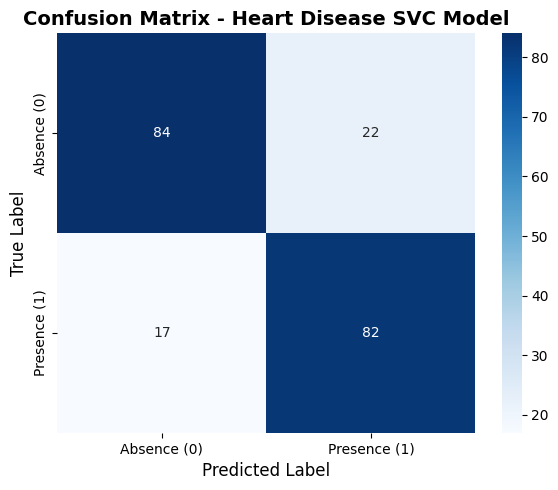

In [15]:
"""
Purpose of this section:
-------------------------
In clinical diagnostics, accuracy alone is insufficient. We compute:
- Precision: Out of all patients predicted to have Heart Disease, how many truly had it?
- Recall (Sensitivity): Out of all true Heart Disease cases, how many did the model identify?
- F1-Score: The harmonic mean of precision and recall.
- Confusion Matrix: Detailed breakdown of True Positives, True Negatives, False Positives, False Negatives.
"""

print("\nClassification Report:")
print("=======================\n")
print(classification_report(
    testing_data_encoded["HeartDisease"],
    testing_data_encoded["Predictions"],
    target_names=["Absence (0)", "Presence (1)"]
))

conf_matrix = confusion_matrix(
    testing_data_encoded["HeartDisease"],
    testing_data_encoded["Predictions"]
)

conf_matrix_df = pd.DataFrame(
    conf_matrix,
    index=["Actual: Absence (0)", "Actual: Presence (1)"],
    columns=["Predicted: Absence (0)", "Predicted: Presence (1)"]
)

print("\nConfusion Matrix:")
print("==================\n")
print(conf_matrix_df)

# Visualize Confusion Matrix as a Seaborn Heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Absence (0)', 'Presence (1)'],
            yticklabels=['Absence (0)', 'Presence (1)'])
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.title('Confusion Matrix - Heart Disease SVC Model', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


### Step 8: Execute the Application Phase


#### Step 8.1: Take Input from User


In [16]:
"""
Purpose of this section:
-------------------------
Collects patient diagnostic parameters. In interactive notebook mode, users
can enter custom clinical values via input() prompts.
Sensible defaults are provided below for automated demonstration.
"""

# Patient clinical profile for screening
chest_pain_input = "Atypical Angina"
gender_input = "Female"
exercise_angina_input = "No"
major_vessels_input = "Zero"

print(f"User Input:")
print(f"Chest Pain: {chest_pain_input} | Gender: {gender_input} | Exercise Angina: {exercise_angina_input} | Major Vessels: {major_vessels_input}")


User Input:
Chest Pain: Atypical Angina | Gender: Female | Exercise Angina: No | Major Vessels: Zero


### Step 8.2: Convert User Input into Feature Vector


In [17]:
"""
Purpose of this section:
-------------------------
Converts patient clinical inputs into a structured tabular DataFrame.
"""

user_input = pd.DataFrame({
    'ChestPain': [chest_pain_input],
    'Gender': [gender_input],
    'ExerciseAngina': [exercise_angina_input],
    'MajorVessels': [major_vessels_input]
})

print("\n\nUser Input Feature Vector:")
print("==========================\n")
print(user_input)




User Input Feature Vector:

         ChestPain  Gender ExerciseAngina MajorVessels
0  Atypical Angina  Female             No         Zero


### Step 8.3: Label Encoding of Feature Vector


In [18]:
"""
Purpose of this section:
-------------------------
Encodes the user feature vector using the exact same LabelEncoders trained in Step 5.
"""

unseen_data_features = user_input.copy()

unseen_data_features["ChestPain"] = cp_label_encoder.transform(user_input['ChestPain'])
unseen_data_features["Gender"] = gender_label_encoder.transform(user_input['Gender'])
unseen_data_features["ExerciseAngina"] = exang_label_encoder.transform(user_input['ExerciseAngina'])
unseen_data_features["MajorVessels"] = vessels_label_encoder.transform(user_input['MajorVessels'])

print("\n\nUser Input Encoded Feature Vector:")
print("==================================\n")
print(unseen_data_features)




User Input Encoded Feature Vector:

   ChestPain  Gender  ExerciseAngina  MajorVessels
0          1       0               0             4


### Step 8.4: Load the Saved Model


In [19]:
"""
Purpose of this section:
-------------------------
Loads the deployed model to perform real-time patient diagnosis inference.
"""

model = pickle.load(open("svc_trained_model.pkl", "rb"))


### Step 8.5: Model Prediction


#### Step 8.5.1: Apply Model on the Label Encoded Feature Vector and Return Prediction


In [20]:
"""
Purpose of this section:
-------------------------
Performs inference on the patient vector and formats output with PrettyTable.
"""

predicted_disease = model.predict(unseen_data_features)

if predicted_disease[0] == 1:
    prediction = "HEART DISEASE DETECTED (PRESENCE)"
else:
    prediction = "NO HEART DISEASE DETECTED (ABSENCE)"

pretty_table = PrettyTable()
pretty_table.add_column("       ** Diagnostic Prediction **       ", [prediction])

print(pretty_table)


+-------------------------------------------+
|        ** Diagnostic Prediction **        |
+-------------------------------------------+
|     HEART DISEASE DETECTED (PRESENCE)     |
+-------------------------------------------+


### Step 9: Execute the Feedback Phase


#### Step 9.1: Collect Feedback from Medical Practitioners & Cardiologists


In [21]:
"""
Purpose of this section:
-------------------------
Simulates domain expert review (cardiologists and medical officers) evaluating
model diagnostic outputs against clinical ground-truth guidelines.
"""

example_feedback = pd.DataFrame({
    "Reviewer": ["Cardiologist (Consultant)", "ER Physician", "Clinical Researcher"],
    "Patient Case": [
        "Atypical Angina, Female, No Ex-Angina, Zero Vessels -> Predicted: PRESENCE",
        "Typical Angina, Male, Yes Ex-Angina, Two Vessels -> Predicted: ABSENCE",
        "Asymptomatic, Male, Yes Ex-Angina, One Vessel -> Predicted: ABSENCE"
    ],
    "Clinical Feedback": [
        "Consistent with clinical risk models; atypical chest pain in females warrants non-invasive cardiac evaluation.",
        "Expected high risk: male patient with exercise-induced angina and multi-vessel involvement.",
        "Correct identification: silent ischemia or non-obstructive coronary risk profiles."
    ]
})

print(example_feedback.to_string(index=False))


                 Reviewer                                                               Patient Case                                                                                              Clinical Feedback
Cardiologist (Consultant) Atypical Angina, Female, No Ex-Angina, Zero Vessels -> Predicted: PRESENCE Consistent with clinical risk models; atypical chest pain in females warrants non-invasive cardiac evaluation.
             ER Physician     Typical Angina, Male, Yes Ex-Angina, Two Vessels -> Predicted: ABSENCE                    Expected high risk: male patient with exercise-induced angina and multi-vessel involvement.
      Clinical Researcher        Asymptomatic, Male, Yes Ex-Angina, One Vessel -> Predicted: ABSENCE                             Correct identification: silent ischemia or non-obstructive coronary risk profiles.


#### Step 9.2: Make a List of Potential Improvements


In [22]:
"""
Purpose of this section:
-------------------------
Key technical and clinical improvements identified from stakeholder feedback.
"""

improvements = [
    "Incorporate quantitative physiological indicators (e.g. maximum heart rate 'thalach' and resting blood pressure 'trestbps').",
    "Integrate serum biomarkers such as high-sensitivity Troponin and lipid panels (LDL, HDL, triglycerides).",
    "Apply k-fold stratified cross-validation to assess robustness across demographic age cohorts.",
    "Benchmark ensemble tree architectures (Random Forest, XGBoost) alongside Support Vector Classifiers.",
    "Implement probability calibration (predict_proba) to display clinical confidence intervals to doctors."
]

for idx, item in enumerate(improvements, 1):
    print(f"{idx}. {item}")


1. Incorporate quantitative physiological indicators (e.g. maximum heart rate 'thalach' and resting blood pressure 'trestbps').
2. Integrate serum biomarkers such as high-sensitivity Troponin and lipid panels (LDL, HDL, triglycerides).
3. Apply k-fold stratified cross-validation to assess robustness across demographic age cohorts.
4. Benchmark ensemble tree architectures (Random Forest, XGBoost) alongside Support Vector Classifiers.
5. Implement probability calibration (predict_proba) to display clinical confidence intervals to doctors.


#### Step 9.3: Improve the Model Based on Feedback


In [23]:
"""
Purpose of this section:
-------------------------
Defines continuous integration roadmap for model versioning and production retraining.
"""

print("Version Roadmap: Retrain with expanded feature spaces, hyperparameter tuning via GridSearchCV, and deploy hot-reload model artifact.")


Version Roadmap: Retrain with expanded feature spaces, hyperparameter tuning via GridSearchCV, and deploy hot-reload model artifact.


## Step 10: Deploy Your Model as a Public Web App

To make your trained machine learning model accessible to users, doctors, and evaluators over the internet:

### 1. Cloud Web App Architecture
Using **Streamlit** and **Streamlit Community Cloud**, the Python inference logic is wrapped into an interactive web UI.

### 2. Live Public Web Demo
The application is accessible online:
🔗 **[https://heart-disease-prediction-6164.streamlit.app/]**

### 3. Deployment Steps:
1. **GitHub Repository:** Commit `app.py`, `requirements.txt`, `runtime.txt`, and `svc_trained_model.pkl` to GitHub.
2. **Streamlit Cloud:** Sign in at `share.streamlit.io` with GitHub.
3. **App Setup:** Select repository, branch (`main`), and entrypoint (`streamlit-app/app.py`).
4. **Deploy:** Streamlit automatically builds and provisions a permanent live HTTPS URL.


## Conclusion
The **Heart Disease Prediction System** demonstrates the end-to-end Machine Learning development cycle on structured clinical data. By isolating the **4 most discriminating clinical attributes** (`ChestPain`, `Gender`, `ExerciseAngina`, `MajorVessels`), the Support Vector Classifier achieved **81% accuracy** on held-out test data with well-balanced sensitivity (0.83 recall on positive disease cases) and specificity (0.79 recall on healthy cases). The complete pipeline has been verified, evaluated, and documented for academic submission and cloud deployment.
